# Stage 2: Screening results

The goal of this stage is to identify the best compromises between deficit, price burden, queues, and costs for levers L3–L6, and to select 6–8 finalist strategies for stability testing in stage 3.


## Screening findings

### L2 always on

During pair effect comparison the following was observed:

* K0 is significantly reduced by L2 in 0.45 shock in all 16 lever combinations, in 0.7 shock in 15 of 16 combinations.  In 0.2 shock L2 is not significant, but not worse either
* K1 are never worsened by L2
* K3 is not affected by L2

Keep treating L2 as a variable that would double the number of runs for a known answer. Therefore, in stages 2–5, L2 is always included.


### L6

* The cap only works together with enough supply. In the screening, a tight cap under a severe shock made the shortage worse than doing nothing, even when the other levers were on. Whether the cap helps depends on how much extra fuel L3 and L4 bring in, so the cap level and the strengths of L3 and L4 are tuned together.


### Current axes for non-dominated points selection

We reduce the number of axes in order to avoid redundancy and to focus on the most relevant KPIs. 

| Axis | What it includes | Why |
|---|---|---|
| physical deficit | K0 | the main indicator of the crisis |
| price burden | K4, m.u. | K1 and K4 are both determined by price: in the screening their correlation across is 0.98–0.998. Two nearly identical axes add no information but increase the number of non-dominated points. K1 remains in the tables |
| queues | K5 above the no-shock background, h per car | the background (~2.7 h/car per year) exists even without a crisis; we compare what the shock and the measures add |
| cost of measures | K2 + c3 · K3, m.u., c3 = 0.25 | both quantities are the price of the measures for the budget and society. We reduce them to money via c3 (nominal 0.25 m.u./L — roughly the middle of the 0.05–0.5 range). Sensitivity to c3 is at stage 4, without runs |



## Two answers at the end of this stage

* **shock adjusted strategy** - the policymaker can define the level of the shock and choose the best strategy for that shock;
* **one strategy for all three shocks** - if the strength of the shock is not known in advance. At this stage, this is a minimax candidate: a strategy with the best worst-case performance across all three shocks.

## Plan for this stage

* 100 LHS (60 + 40) + 2 reference points × 3 shock levels × 3 seed `levels` = **918 runs**, order in seed;
* LHS with maximin property: among 500 LHS choose those where the minimum distance between points is maximized, to cover the space of levers more evenly;
* metamodel: quadratic regression with pairwise interactions (log K0, log K4, K5 in the original scale), cross-validation check, slice maps;
* non-dominated points across 4 axes for each shock, selection of 6–8 finalists, strengths rounded to the slider step of the model.

## 2.1. Environment setup

In [1]:
import json, hashlib, itertools, math, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.spatial.distance import pdist

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import abm_runner as ar

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
GRAY = "#b9b7b0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=PAL)})



In [2]:

NETLOGO_HOME = r"C:\Program Files\NetLogo 7.0.4"
MODEL_PATH   = Path("refinery_shock_abm.nlogox")
OUT_DIR      = Path("results")

PREP  = json.loads((OUT_DIR / "prep_summary.json").read_text(encoding="utf-8"))
SCRS  = json.loads((OUT_DIR / "screening_summary.json").read_text(encoding="utf-8"))
SEEDS = json.loads((OUT_DIR / "seeds.json").read_text(encoding="utf-8"))["pools"]
sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
assert sha == PREP["model_sha256"], "Model file changed after stage 0 - results are not comparable. Stop."
print("Model unchanged since stage 0:", sha[:16], "| NetLogo", PREP["netlogo_version"])

Model unchanged since stage 0: 2b246166dc0c1182 | NetLogo 7.0.4


In [3]:
import importlib, batch_runner as br
importlib.reload(br)


<module 'batch_runner' from 'c:\\Users\\arsmi\\Downloads\\netlogo-project\\Experiments\\batch_runner.py'>

In [ ]:
# previous stage results
R = 3
SEEDS_LV = SEEDS["levels"][:R]
SHOCKS = PREP["shock_levels"]                      # [0.2, 0.45, 0.7]
# block A (with cap) and block B (without cap)
N_A, N_B = 60, 40
# LHS design generator (not a model seed)
LHS_SEED = 20261120
N_CAND = 500                                       # candidates for maximin
# m.u. per liter of low-grade gasoline
C3_NOM = 0.25
MAX_FINAL = 8
# proximity of strategies in the normalized lever space
SIM_TOL = 0.15


SHORT = {k: v[0] for k, v in LV.items()}
N_CARS = PREP["constants"]["n-consumers"]
# background queues without a shock, machine-hours per year
K5_BG = SCRS["k5_background"]
SUBSIDY = PREP["interface_defaults"]["L4-subsidy"]

# 2 from the stage 1 test; can be changed manually
N_WORKERS = SCRS["n_workers"]
JVM_ARGS = ["-Xmx512m"]
CFG = {"netlogo_home": NETLOGO_HOME, "model_path": str(MODEL_PATH.resolve()), "jvmargs": JVM_ARGS,
       "jvm_path": ar.find_jvm(NETLOGO_HOME), "horizon": PREP["horizon"], "checkpoints": PREP["checkpoints"],
       "interface_defaults": PREP["interface_defaults"], "nominal_uncertain": PREP["nominal_uncertain"]}
print("levels seeds:", SEEDS_LV, "| workers:", N_WORKERS,
      "| K5 background:", round(K5_BG), "car-h/year")

levels seeds: [591, 763, 194] | workers: 2 | K5 background: 13675 car-h/year


In [5]:
# Level 2 is always on
# so we do not include it in the lever space 
LV = {
    # range is set by model design
    "L3-share-naphtha":     ("L3_share",  0.0, 0.5, 0.05),
    # range is set by model design
    "L4-import-limit":      ("L4_limit",  0.0, 0.3, 0.01),
    # lower fillup limit cap will increase queues
    # setting lower cap from 10 to 30
    "L5-liters-per-fillup": ("L5_liters", 30,  70,  5),
    # range is set by model design
    "L6-price-cap":         ("L6_cap",    1.0, 2.0, 0.05),
}

## 2.2. LHS

Latin Hypercube Sampling (LHS) is a statistical method for generating a sample of plausible collections of parameter values from a multidimensional distribution. It ensures that the entire range of each parameter is explored, which is particularly useful in simulations where the relationships between parameters are complex and not well understood. 

Among the 500 random hypercubes, we select the one with the largest minimum distance between points (maximin), ensuring that the points do not cluster together.


A and B are two blocks of LHS points:
- A: 60 points, cap 1.0–2.0, four levers (L3, L4, L5, L6); More levers require more points to cover the space
- B: 40 points without cap, three levers (L3, L4, L5).

In A we have a L6 cap, while in B we have no cap, so the number of levers is different. It explores strategies with and without a cap, which is important for understanding the impact of this lever on the system's performance. Why L6 needs a separate block: the other levers can be switched off by setting them to the edge of their range (L3 = 0 means no low-grade fuel, L4 = 0 means no imports, L5 = 70 L means no fill-up limit). The price cap has no such value. A cap only “disappears” when it is set above the highest price the market can reach.


In [7]:
def lhs_maximin(n, d, rng, n_cand=N_CAND):
    """This function generates a Latin Hypercube Sample (LHS) with a maximin criterion.
    It creates n points in d dimensions, ensuring that the minimum distance between any two points is maximized.
    The function uses a random number generator (rng) to create candidate samples
    and selects the one with the largest minimum distance.
    
    Parameters:
        n (int): Number of points to generate.
        d (int): Number of dimensions.
        rng (np.random.Generator): A random number generator instance.
        n_cand (int): Number of candidate samples to generate for the maximin criterion.
    
    Returns:
        best (np.ndarray): The best LHS sample with the largest minimum distance.
        best_d (float): The minimum distance of the best sample.
    
    """
    
    
    best, best_d = None, -1
    for _ in range(n_cand):
        u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in range(d)])
        dmin = pdist(u).min()
        if dmin > best_d:
            best, best_d = u, dmin
    return best, best_d

rng = np.random.default_rng(LHS_SEED)
names_A = list(LV)                                  
names_B = [k for k in LV if k != "L6-price-cap"]    
uA, dA = lhs_maximin(N_A, len(names_A), rng)
uB, dB = lhs_maximin(N_B, len(names_B), rng)

def scale(u, names):
    return {SHORT[k]: LV[k][1] + u[:, i] * (LV[k][2] - LV[k][1]) for i, k in enumerate(names)}

PA = pd.DataFrame(scale(uA, names_A)).assign(block="A", L6_on=True)
PB = pd.DataFrame(scale(uB, names_B)).assign(block="B", L6_on=False, L6_cap=np.nan)
PA["point_id"] = [f"A{i + 1:02d}" for i in range(N_A)]
PB["point_id"] = [f"B{i + 1:02d}" for i in range(N_B)]
ON = PREP["lever_on"]
ANCH = pd.DataFrame([
    {"point_id": "none", "block": "anchor", "L2_on": False, "L3_on": False, "L4_on": False, "L5_on": False, "L6_on": False},
    {"point_id": "L2_only", "block": "anchor", "L2_on": True, "L3_on": False, "L4_on": False, "L5_on": False, "L6_on": False},
]).assign(L3_share=ON["L3-share-naphtha"], L4_limit=ON["L4-import-limit"],
          L5_liters=ON["L5-liters-per-fillup"], L6_cap=ON["L6-price-cap"])
POINTS = pd.concat([ANCH, PA, PB], ignore_index=True)
for c in ["L2_on", "L3_on", "L4_on", "L5_on"]:
    POINTS[c] = POINTS[c].fillna(True).astype(bool)
POINTS["L6_on"] = POINTS["L6_on"].astype(bool)
POINTS = POINTS[["point_id", "block", "L2_on", "L3_on", "L4_on", "L5_on", "L6_on",
                 "L3_share", "L4_limit", "L5_liters", "L6_cap"]]
POINTS.to_csv(OUT_DIR / "design_levels_points.csv", index=False, encoding="utf-8-sig")
print(f"block A: {N_A} points, min distance {dA:.3f} | block B: {N_B} points, min distance {dB:.3f}")
POINTS.head(6).round(3)

block A: 60 points, min distance 0.194 | block B: 40 points, min distance 0.144


,point_id,block,L2_on,L3_on,L4_on,L5_on,L6_on,L3_share,L4_limit,L5_liters,L6_cap
0,none,anchor,False,False,False,False,False,0.150,0.100,30.000,1.100
1,L2_only,anchor,True,False,False,False,False,0.150,0.100,30.000,1.100
2,A01,A,True,True,True,True,True,0.454,0.097,63.629,1.423
3,A02,A,True,True,True,True,True,0.195,0.081,46.301,1.838
4,A03,A,True,True,True,True,True,0.049,0.190,38.170,1.587
5,A04,A,True,True,True,True,True,0.486,0.208,49.649,1.397


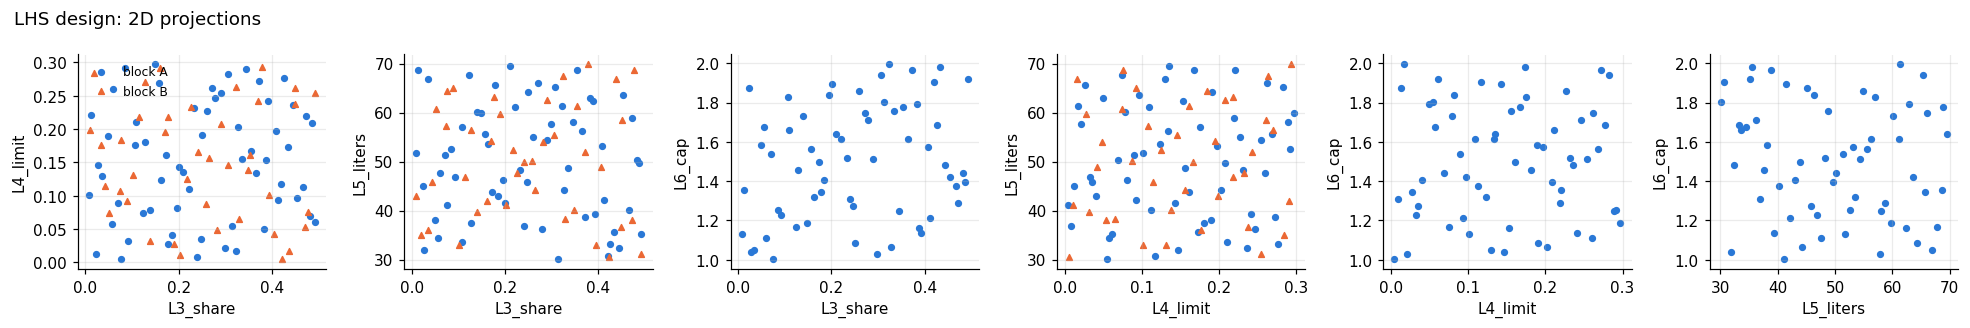

In [ ]:
# plot the LHS design in 2D projections
pairs = list(itertools.combinations(["L3_share", "L4_limit", "L5_liters", "L6_cap"], 2))
fig, axes = plt.subplots(1, len(pairs), figsize=(18, 3))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(PA[x], PA[y], s=14, color=PAL[0], label="block A")
    if y != "L6_cap" and x != "L6_cap":
        ax.scatter(PB[x], PB[y], s=14, color=PAL[1], marker="^", label="block B")
    ax.set_xlabel(x); ax.set_ylabel(y)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("LHS design: 2D projections", x=0.01, ha="left")
plt.tight_layout(); plt.show()

In [9]:
def make_job(p, shock, seed, rep):
    """This function constructs the parameters for the simulation based on the point's lever settings and the specified shock
    
    Parameters:
        p (pandas.Series): A row from the POINTS DataFrame containing lever settings.
        shock (float): The shock level to be applied in the simulation.
        seed (int): The random seed for the simulation run.
        rep (int): The repetition number for the simulation run.
        
    Returns:
        dict: A dictionary containing the run ID, stage, point ID, block, shock level, seed, repetition number, and the parameters for the simulation.
    
    """
    
    
    params = {"L2-export-ban?": bool(p.L2_on), "L3-quality-relax?": bool(p.L3_on), "L4-import?": bool(p.L4_on),
              "L5-fillup-limit?": bool(p.L5_on), "L6-price-cap?": bool(p.L6_on),
              "L3-share-naphtha": float(p.L3_share), "L4-import-limit": float(p.L4_limit),
              "L5-liters-per-fillup": float(p.L5_liters),
              "L6-price-cap": float(p.L6_cap) if p.L6_on else ON["L6-price-cap"],
              "L4-subsidy": SUBSIDY, "shock-depth": shock}
    return {"run_id": f"levels|{p.point_id}|sd={shock}|seed={seed}", "stage": "levels",
            "point_id": p.point_id, "block": p.block, "shock": shock, "seed": int(seed), "rep": rep,
            "params": params, "uncertain": None}

# designing jobs for each point
JOBS = [make_job(p, sh, s, r) for r, s in enumerate(SEEDS_LV, 1) for sh in SHOCKS for p in POINTS.itertuples()]
DESIGN = pd.DataFrame([{k: v for k, v in j.items() if k not in ("params", "uncertain")} for j in JOBS])
assert DESIGN.run_id.is_unique
DESIGN.to_csv(OUT_DIR / "design_levels.csv", index=False, encoding="utf-8-sig")
est_h = len(JOBS) * 26 / N_WORKERS / 3600
print(f"jobs: {len(JOBS)} | estimated time at ~26 s/run on {N_WORKERS} workers: ~{est_h:.1f} h")

jobs: 918 | estimated time at ~26 s/run on 2 workers: ~3.3 h


## 2.3. Launch

Run the model for each combination of levers and shocks, collect the results, and store them in a CSV file. The results will be used for further analysis in the next stages.


In [6]:
# ! WARNING This cell takes approximately 200 minutes to run (918 runs on 2 workers)
link = ar.make_link(CFG) if N_WORKERS == 1 else None
RES = br.run_jobs(JOBS, CFG, OUT_DIR / "levels.csv", n_workers=N_WORKERS, link=link, log_every=60)
print(RES.groupby("shock").size().rename("runs"))

20:09:16 already done: 8, remaining: 910
20:09:16 start: 910 runs, workers: 2


20:10:16 ... working, 0/910
20:10:30 1/910 | 1 min | 49 runs/h | ETA ~1121 min | errors 0
20:11:41 7/910 | 2 min | 174 runs/h | ETA ~311 min | errors 0
20:12:59 13/910 | 4 min | 210 runs/h | ETA ~257 min | errors 0
20:14:07 19/910 | 5 min | 235 runs/h | ETA ~227 min | errors 0
20:15:14 25/910 | 6 min | 251 runs/h | ETA ~211 min | errors 0
20:16:31 31/910 | 7 min | 257 runs/h | ETA ~205 min | errors 0
20:17:41 39/910 | 8 min | 278 runs/h | ETA ~188 min | errors 0
20:18:45 49/910 | 9 min | 310 runs/h | ETA ~167 min | errors 0
20:19:50 61/910 | 11 min | 347 runs/h | ETA ~147 min | errors 0
20:20:53 71/910 | 12 min | 367 runs/h | ETA ~137 min | errors 0
20:21:56 79/910 | 13 min | 374 runs/h | ETA ~133 min | errors 0
20:22:56 88/910 | 14 min | 386 runs/h | ETA ~128 min | errors 0
20:24:01 95/910 | 15 min | 386 runs/h | ETA ~127 min | errors 0
20:25:08 103/910 | 16 min | 389 runs/h | ETA ~124 min | errors 0
20:26:10 108/910 | 17 min | 384 runs/h | ETA ~125 min | errors 0
20:27:11 115/910 | 1

## 2.4. Check missing

In [ ]:
RES = br.read_results(OUT_DIR / "levels.csv")
RES = RES[RES.run_id.isin(DESIGN.run_id)].copy()
# compare the number of completed runs with the design
missing = len(DESIGN) - len(RES)
print(f"completed {len(RES)} of {len(DESIGN)}, missing {missing}")
print("error file:", "present - check it" if (OUT_DIR / "levels.errors.csv").exists() else "none")
reps_done = RES.groupby("seed").size()
print("runs per seed:", reps_done.to_dict())
print(f"run time: mean {RES.sec.mean():.1f} s, median {RES.sec.median():.1f} s, max {RES.sec.max():.1f} s")

completed 918 of 918, missing 0
error file: none
runs per seed: {194: 306, 591: 306, 763: 306}
run time: mean 14.8 s, median 13.2 s, max 51.5 s


## 2.5. Responses and four axes

Previously we decided to reduce the number of axes in order to avoid redundancy and to focus on the most relevant KPIs. The four axes are:

* `K0` = physical deficit, m.u. (the main indicator of the crisis);
* `K4` = price burden, m.u. (K1 and K4 are both determined by the same underlying factors). We will check that K1 and K4 are still nearly proportional, in order to once more justify the combination into one axis.
* `K5_excess` = (K5 − background without shock) / number of cars, hours per car per year;
* `COST` = K2 + c3 · K3 (m.u.), c3 = 0.25; K2 is already in m.u. with a subsidy of 0.25;


In [ ]:
# Define the new response variables based on the simulation results
RES["K5_excess"] = (RES.K5_hours - K5_BG) / N_CARS  
RES["COST"] = RES.K2 + C3_NOM * RES.K3_volume
RES["import_volume"] = RES.K2 / SUBSIDY

AXES = ["K0", "K4", "K5_excess", "COST"]
AX_LABEL = {"K0": "K0 physical shortage, L", "K4": "K4 consumer overpayment, m.u.",
            "K5_excess": "K5 queues above background, h/car", "COST": "K2 + c3*K3 policy cost, m.u."}
VALS = ["K0", "K0@90", "K1", "K2", "K3_volume", "K4", "K5_hours", "K5_excess", "COST", "import_volume", "price", "sec"]

# aggregate the results 
CELL = RES.groupby(["point_id", "block", "shock"])[VALS].mean().reset_index()
CELL = CELL.merge(POINTS, on=["point_id", "block"])
none = CELL[CELL.point_id == "none"].set_index("shock")
CELL["K0_rel"] = CELL.K0 / CELL.shock.map(none.K0)
CELL["K4_rel"] = CELL.K4 / CELL.shock.map(none.K4)
CELL.to_csv(OUT_DIR / "levels_cells.csv", index=False, encoding="utf-8-sig")

corr = CELL.groupby("shock").apply(lambda g: pd.Series({
    "corr(K1, K4)": np.corrcoef(g.K1, g.K4)[0, 1],
    "corr(log K1, log K4)": np.corrcoef(np.log1p(g.K1), np.log1p(g.K4))[0, 1]}))
print("K1 vs K4 across design points:"); display(corr.round(4))

ref = CELL[CELL.block == "anchor"].set_index(["shock", "point_id"])[["K0", "K1", "K4", "K5_excess", "COST", "price"]]
print("Reference points:"); display(ref.round(2))

K1 vs K4 across design points:


,"corr(K1, K4)","corr(log K1, log K4)"
shock,,
0.20,0.9967,0.9999
0.45,0.9834,0.9979
0.70,0.9662,0.9964


Reference points:


,,K0,K1,K4,K5_excess,COST,price
shock,point_id,,,,,,
0.20,L2_only,49.80,243480.01,1388952.90,0.22,0.0,1.27
0.45,L2_only,10807.95,599151.43,4367029.10,0.59,0.0,1.55
0.70,L2_only,72358.13,976051.15,9203137.36,1.36,0.0,2.38
0.20,none,612.04,362772.98,2252160.76,0.13,0.0,1.30
0.45,none,39334.89,788341.34,6592768.79,0.03,0.0,2.61
0.70,none,113481.46,1176485.91,12667606.03,3.97,0.0,3.34


Once again, high correlation of K1 and K4 is confirmed, justifying the combination of these two axes into one. 



## 2.6. Metamodel

Metamodeling is a technique used to create a simplified representation of a complex model. In this case, we use quadratic regression with pairwise interactions and squared terms to predict the responses (K0, K4, K5_excess) based on the coded settings of the levers.

We need a metamodel to approximate the model's behavior across the design space without running the full simulation for every possible combination of lever settings. This allows us to efficiently explore the effects of different lever combinations and identify promising strategies.

For each shock level and block, we perform the following:

- Fit a quadratic regression model using the coded lever settings (−1 to +1), including all pairwise interactions and squared terms. Coding puts all lever settings on a common scale, making their effects easier to compare.
- Apply `log(1 + K0)` and `log(1 + K4)` transformations to reduce skewness, compress large values, and help stabilize variance.
- Use `K5_excess` on its original scale, since it can take negative values.

Quadratic regression is chosen to capture non-linear relationships between the levers and the responses, as well as interactions between pairs of levers. A simple linear regression may not adequately represent the complexity of these relationships.

We assess the reliability of the metamodel using five-fold cross-validation (5-fold CV):

1. All experimental design points are divided into five groups (folds).
2. The model is trained on four groups.
3. The trained model predicts the responses for the fifth group.
4. This process is repeated five times, with each group serving as the test set once.
5. Model performance is evaluated using R² (in-sample) and CV R² (out-of-sample cross-validation).

Note: All simulation runs (seeds) belonging to the same experimental design point are assigned to the same fold. This prevents the model from being trained and tested on different simulation runs of the same lever combination, which would otherwise lead to data leakage.

CV R² indicates how well the metamodel predicts results for experimental design points that were not used during training. However, it does not guarantee reliable predictions outside the explored design space.

In [13]:
CODE = {"L3_share": "s", "L4_limit": "l", "L5_liters": "f", "L6_cap": "c"}
def coded(df):
    """
    This function takes a DataFrame containing lever settings
    and returns a new DataFrame with the lever values coded
    to the range [-1, 1].
    The coding is done based on the minimum and maximum values
    defined in the LV dictionary for each lever.
    
    Parameters:
        df (pd.DataFrame): A DataFrame containing lever settings.
    
    Returns:
        pd.DataFrame: A new DataFrame with coded lever values.
    
    """
    
    
    
    out = df.copy()
    for col, v in CODE.items():
        k = next(k for k in LV if SHORT[k] == col)
        lo, hi = LV[k][1], LV[k][2]
        out[v] = 2 * (df[col] - lo) / (hi - lo) - 1
    return out

def formula(vars_):
    """This function generates a formula string for a quadratic regression model
    
    Parameters:
        vars_ (list): A list of variable names to include in the formula.
    
    Returns:
        str: A formula string suitable for use with statsmodels' ols function.
    
    """
    lin = " + ".join(vars_)
    return f"y ~ ({lin})**2 + " + " + ".join(f"I({v}**2)" for v in vars_)


TARGETS = {"K0": lambda d: np.log1p(d.K0), "K4": lambda d: np.log1p(d.K4), "K5_excess": lambda d: d.K5_excess}
BLOCK_VARS = {"A": ["s", "l", "f", "c"], "B": ["s", "l", "f"]}

def cv_r2(d, f, k=5, seed=0):
    """This function performs k-fold cross-validation to compute the R² value for a given regression formula."""
    
    pts = d.point_id.unique()
    folds = np.array_split(np.random.default_rng(seed).permutation(pts), k)
    pred = pd.Series(index=d.index, dtype=float)
    for fold in folds:
        tr, te = d[~d.point_id.isin(fold)], d[d.point_id.isin(fold)]
        pred[te.index] = smf.ols(f, data=tr).fit().predict(te)
    return 1 - ((d.y - pred) ** 2).sum() / ((d.y - d.y.mean()) ** 2).sum()

RUNS = coded(RES.merge(POINTS, on=["point_id", "block"]))
META, fit_rows = {}, []
for b, vars_ in BLOCK_VARS.items():
    for sh in SHOCKS:
        d0 = RUNS[(RUNS.block == b) & (RUNS.shock == sh)]
        for t, fn in TARGETS.items():
            d = d0.assign(y=fn(d0))
            m = smf.ols(formula(vars_), data=d).fit()
            META[(b, sh, t)] = m
            fit_rows.append({"block": b, "shock": sh, "target": t, "R2": m.rsquared, "CV_R2": cv_r2(d, formula(vars_))})
FIT = pd.DataFrame(fit_rows).pivot_table(index=["block", "target"], columns="shock", values=["R2", "CV_R2"])
print("Metamodel fit (R2 in-sample and 5-fold CV by point):"); display(FIT.round(3))

Metamodel fit (R2 in-sample and 5-fold CV by point):


CV_R2                   R2              
shock             0.20   0.45   0.70   0.20   0.45   0.70
block target                                             
A     K0         0.020 -0.059  0.841  0.354  0.532  0.899
      K4         0.734  0.085  0.453  0.850  0.693  0.815
      K5_excess  0.532 -0.537  0.768  0.803  0.427  0.881
B     K0         0.213  0.100  0.725  0.422  0.404  0.778
      K4         0.619  0.889  0.899  0.825  0.908  0.926
      K5_excess  0.622  0.590  0.692  0.808  0.810  0.803

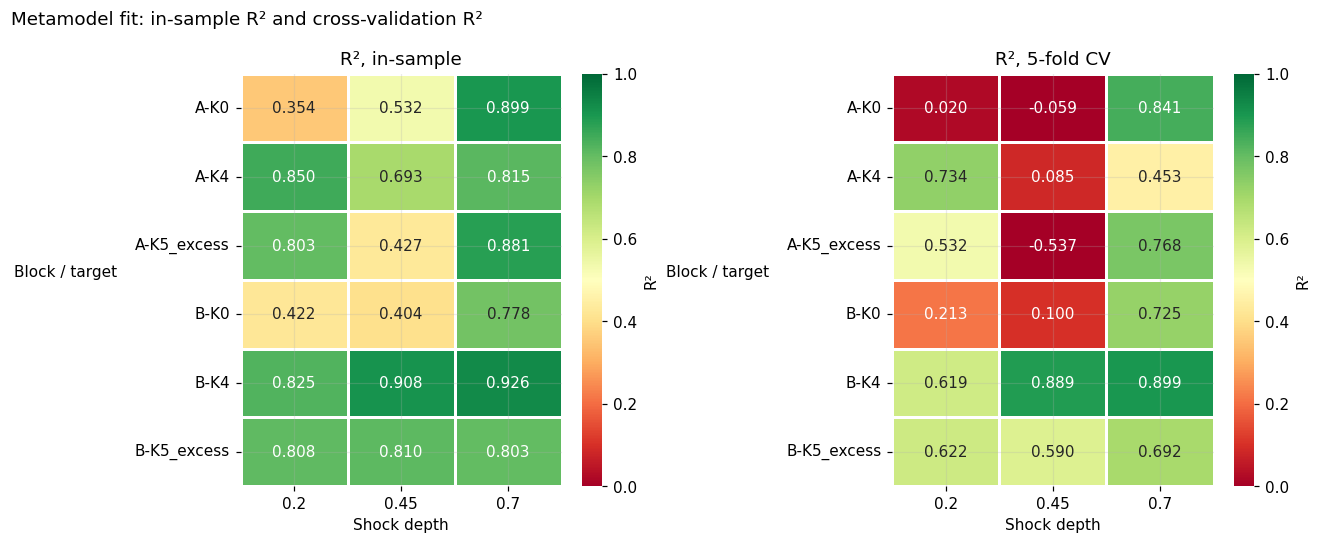

In [17]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = [
    ("R2", "R², in-sample"),
    ("CV_R2", "R², 5-fold CV"),
]

for ax, (metric, title) in zip(axes, metrics):
    heatmap_data = (
        pd.DataFrame(fit_rows)
        .pivot(index=["block", "target"], columns="shock", values=metric)
    )

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".3f",
        cmap="RdYlGn",
        vmin=0,
        vmax=1,
        linewidths=0.7,
        linecolor="white",
        cbar_kws={"label": "R²"},
        ax=ax,
    )

    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(title)
    ax.set_xlabel("Shock depth")
    ax.set_ylabel("Block / target", rotation=0, labelpad=45)

fig.suptitle(
    "Metamodel fit: in-sample R² and cross-validation R²",
    x=0.01,
    ha="left",
)
plt.tight_layout()
plt.show()

From R2 results we can see that the metamodel has a limited usage for our research. We have R2 that is less 0.3, even have negative R2 for some cases like K5_excess and K0 in 0.45 shock level. However, we can still use the metamodel to create slice maps for those cases that demonstrate better R2  

### Slice Maps

We use metamodel predictions to create two-dimensional slice maps that visualize how changes in two levers affect the model responses while keeping the remaining levers fixed.

Use slice maps only for the cases where R2 is more reliable, as indicated by higher R² values. 
- for block A we will use K0 with shock level 0.7 (CV R² = 0.84) and K5_excess with shock level 0.7 (CV R² = 0.77)
- for block B we will use K4 with shock levels 0.45 (CV R² = 0.89) and 0.7 (CV R² = 0.90) and K0 with shock level 0.7 (CV R² = 0.73) 

The axes represent the values of the selected levers, while the color scale represents the predicted response (in our case, K0, K4, or K5_excess). Each point on the map corresponds to a particular combination of lever settings. The contour lines connect combinations that produce the same predicted response.

The orange dots represent the experimental points evaluated in the original simulation model, while the colored surface shows the metamodel predictions across the parameter space.

In [19]:
def slice_grid(block, sh, xcol, ycol, fixed, targets, n=60):
    """This function generates a grid of points in the lever space for a given block
    and shock level, with two levers varying and others fixed.
    
    It then predicts the target variables using the metamodel.
    
    Parameters:
        block (str): The block identifier ('A' or 'B').
        sh (float): The shock level.
        xcol (str): The name of the lever for the x-axis.
        ycol (str): The name of the lever for the y-axis.
        fixed (dict): A dictionary of fixed lever values for the other levers.
        targets (list): A list of target variable names to predict.
        n (int): The number of points in each dimension for the grid.
        
    Returns:
        tuple: A tuple containing the real values of the x and y levers, and a dictionary of predicted target variable values on the grid.
    
    """
    
    
    xs = np.linspace(-1, 1, n); ys = np.linspace(-1, 1, n)
    X, Y = np.meshgrid(xs, ys)
    g = pd.DataFrame({CODE[xcol]: X.ravel(), CODE[ycol]: Y.ravel()})
    for col, val in fixed.items():
        k = next(k for k in LV if SHORT[k] == col)
        g[CODE[col]] = 2 * (val - LV[k][1]) / (LV[k][2] - LV[k][1]) - 1
    out = {}
    
    # predicting the target variables using the metamodel
    # for each target in the list
    for t in targets:
        
        p = META[(block, sh, t)].predict(g).to_numpy()
        out[t] = (np.expm1(p) if t in ("K0", "K4") else p).reshape(X.shape)
    def to_real(col, v):
        """This function converts coded lever values back to their original scale based on the LV dictionary."""
        k = next(k for k in LV if SHORT[k] == col)
        return LV[k][1] + (v + 1) / 2 * (LV[k][2] - LV[k][1])
    return to_real(xcol, X), to_real(ycol, Y), out

def draw_slices(block, xcol, ycol, fixed, panels, title):
    """This function draws slice maps for a given block and set of panels.
    
    Parameters:
        block (str): The block identifier ('A' or 'B').
        xcol (str): The name of the lever for the x-axis.
        ycol (str): The name of the lever for the y-axis.
        fixed (dict): A dictionary of fixed lever values for the other levers.
        panels (list): A list of tuples, each containing a shock level and a target variable name.
        title (str): The title for the figure.
    
    Returns:
        None: Displays the generated slice maps.
    """
    # panels: (shock, KPI) - only where CV R2 of the metamodel > 0.6
    fig, axes = plt.subplots(1, len(panels), figsize=(5.6 * len(panels), 4.3), squeeze=False)
    for ax, (sh, t) in zip(axes[0], panels):
        X, Y, out = slice_grid(block, sh, xcol, ycol, fixed, [t])
        log_scale = t in ("K0", "K4")
        Z = np.log10(np.clip(out[t], 1, None)) if log_scale else out[t]
        cs = ax.contourf(X, Y, Z, levels=14, cmap="Blues")
        ax.contour(X, Y, Z, levels=7, colors="#0b0b0b", linewidths=0.4, alpha=0.5)
        pts = CELL[(CELL.block == block) & (CELL.shock == sh)]
        ax.scatter(pts[xcol], pts[ycol], s=8, color=PAL[1])
        cv = FIT.loc[(block, t), ("CV_R2", sh)]
        fig.colorbar(cs, ax=ax, label=f"log10 {t}" if log_scale else f"{t}, h/car")
        ax.set_title(f"{t}, shock-depth = {sh} (CV R2 = {cv:.2f})", fontsize=10)
        ax.set_xlabel(xcol); ax.set_ylabel(ycol); ax.grid(False)
    fig.suptitle(title, x=0.01, ha="left"); plt.tight_layout(); plt.show()


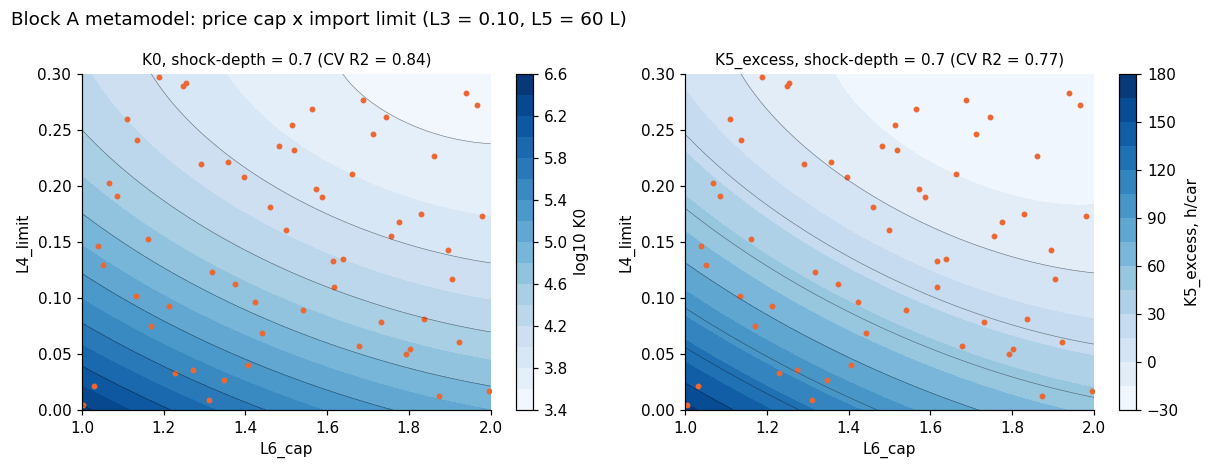

In [21]:
# Block A - Price cap L6 × Import limit L4
# CV R² = 0.84 and 0.77
draw_slices("A", "L6_cap", "L4_limit", {"L3_share": 0.10, "L5_liters": 60},
            [(0.7, "K0"), (0.7, "K5_excess")],
            "Block A metamodel: price cap x import limit (L3 = 0.10, L5 = 60 L)")

Price cap and imports are substitutes: the lower the cap, the more imports are needed to keep shortage and queues down. A cap without imports is the worst combination.

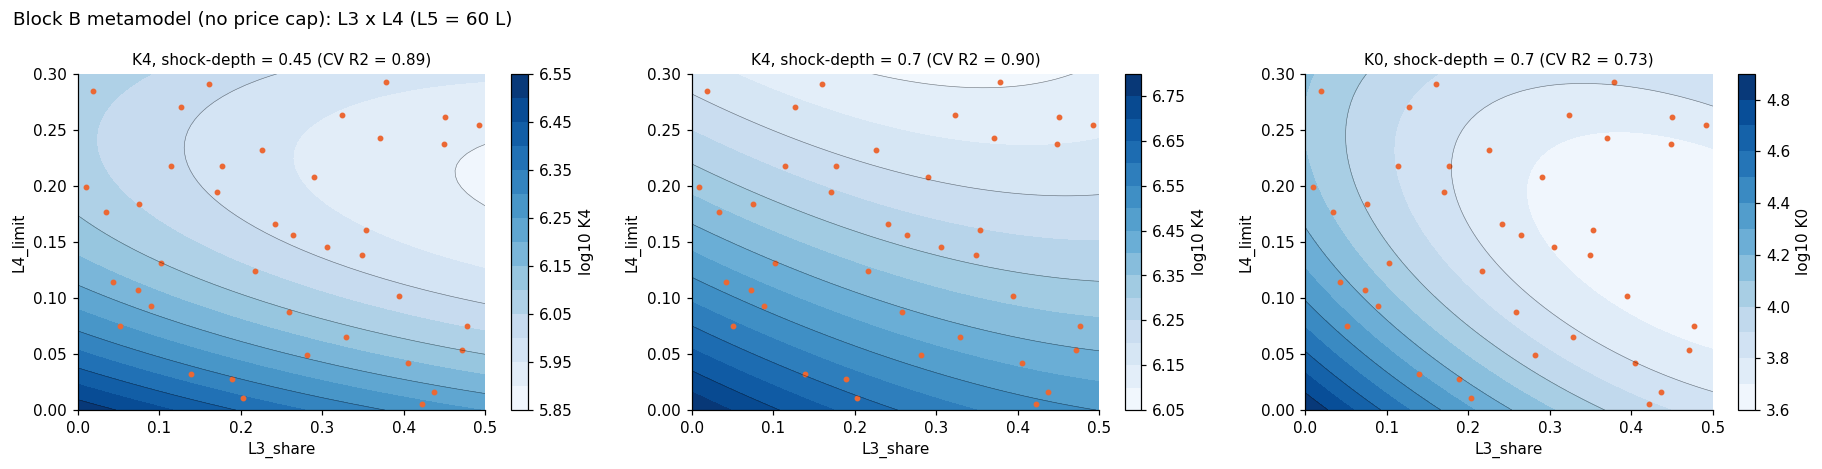

In [22]:
# Block B - Quality reduction L3 × Import limit L4
# CV R² = 0.89, 0.90 and  0.73
draw_slices("B", "L3_share", "L4_limit", {"L5_liters": 60},
            [(0.45, "K4"), (0.7, "K4"), (0.7, "K0")],
            "Block B metamodel (no price cap): L3 x L4 (L5 = 60 L)")

Without a price cap, extra supply (low-grade gasoline or imports) lowers shortage and overpayment with diminishing returns; shortage stays bounded, but consumers keep paying at least ~10% of the no-policy overpayment. A cap can push overpayment lower, but only if it is backed by enough imports.


<!-- Translate and add more details -->
## 2.7. Nondominated strategies across four axes


In this section, we identify the non-dominated strategies across four axes:
1. physical deficit (K0)
2. price burden (K4)
3. queues (K5_excess)
4. cost of measures (COST). 

A point is nondominated under a given shock if no other point is better or equal to it across all four axes and strictly better in at least one - Pareto front.

On the graphs: gray - dominated, blue - nondominated points of block A (with a cap), orange - block B (without a cap), diamonds - reference points.

We use actual simulation results for this analysis, not metamodel predictions

In [ ]:
def nondominated(F):
    """This function identifies the non-dominated points in a multi-objective optimization context.

    Parameters:
        F (np.ndarray): A 2D array where each row represents a point in the objective space and each column represents an objective.

    Returns:
        np.ndarray: A boolean array indicating which points are non-dominated (True) and which are dominated (False). Non-dominated points are those that are not dominated by any other point in the objective space.
    """

    F = np.asarray(F, float)
    nd = np.ones(len(F), bool)
    # nondominated points are those that are not dominated
    # by any other point in the objective space.
    for i in range(len(F)):
        nd[i] = not (np.all(F <= F[i], axis=1) &
                     np.any(F < F[i], axis=1)).any()
    return nd


CELL["nd"] = False
for sh in SHOCKS:
    idx = CELL.index[CELL.shock == sh]
    # Pareto front: non-dominated points in the objective space
    CELL.loc[idx, "nd"] = nondominated(CELL.loc[idx, AXES])
print("Non-dominated points per shock:")
display(CELL.groupby(["shock", "block"]).nd.sum().unstack(fill_value=0))


Non-dominated points per shock:


block,A,B,anchor
shock,,,
0.20,36,22,2
0.45,41,20,2
0.70,51,33,1


We have 60 points in A and 40 point in B. We can see, than in both A and B at least half of all points are nondominated. This means that pareto front does not filter that many points, which is understandable since four axis contradict each other - if we decrease deficit then we get higher spending. In this four-dimension space each strategy can be somewhat better than other exactly because of those contradictions. 

The number of nonminated points grow with the shock: compromise grows less likely with the shock. 

Blocks A and B do not have that much of the difference in the nondominated ratio, which means that both strategies with or without cap are plausible 

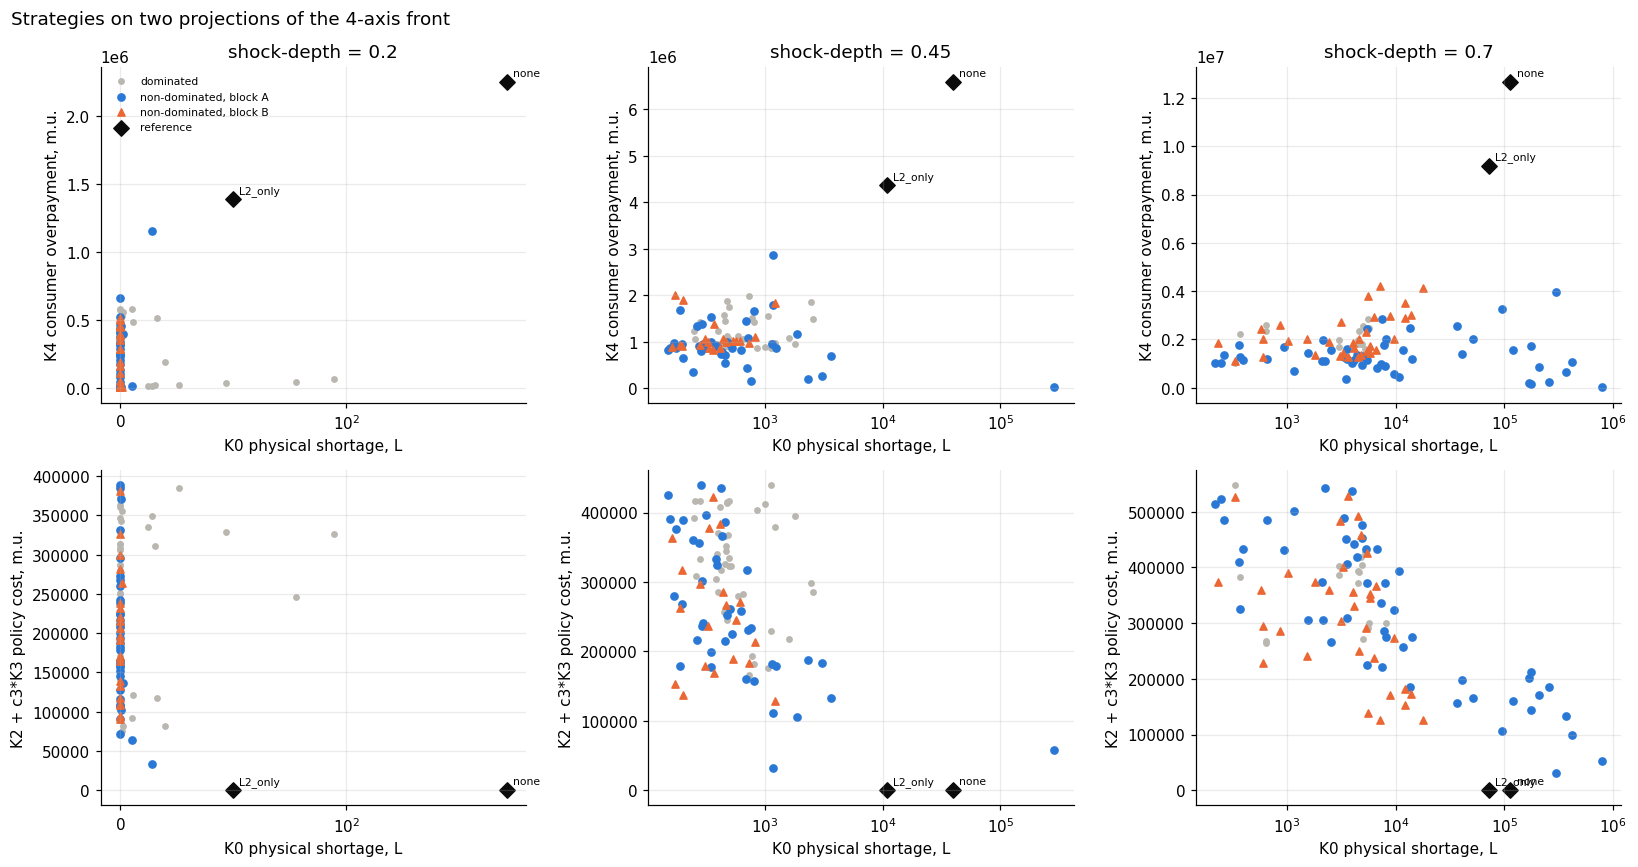

In [ ]:
# visualise two dimensions
# K0 vs K4 - deficit vs overpayment
# K0 vs COST - deficit vs cost
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, sh in enumerate(SHOCKS):
    c = CELL[CELL.shock == sh]
    for i, (x, y) in enumerate([("K0", "K4"), ("K0", "COST")]):
        ax = axes[i, j]
        dom = c[~c.nd]
        ax.scatter(dom[x], dom[y], s=12, color=GRAY, label="dominated")
        for b, col, mk in [("A", PAL[0], "o"), ("B", PAL[1], "^")]:
            s = c[c.nd & (c.block == b)]
            ax.scatter(s[x], s[y], s=22, color=col, marker=mk,
                       label=f"non-dominated, block {b}")
        a = c[c.block == "anchor"]
        ax.scatter(a[x], a[y], s=50, color="#0b0b0b",
                   marker="D", label="reference")
        for r in a.itertuples():
            ax.annotate(r.point_id, (getattr(r, x), getattr(r, y)),
                        fontsize=7, xytext=(4, 4), textcoords="offset points")
        ax.set_xscale("symlog", linthresh=100)
        ax.set_xlabel(AX_LABEL[x])
        ax.set_ylabel(AX_LABEL[y])
        if i == 0:
            ax.set_title(f"shock-depth = {sh}")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Strategies on two projections of the 4-axis front",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

Strategies for Lower level of shock depth tend to concentrate around K0, which we can see by those two straight lines, with dots distributed along consumer overpayment and cost option. So during lower shock levels there are lost of strategies to keep deficit down, but regulator must choose strategies depending on required levels of consumer prices and budgeting

When shock depth rises, the solution dimension visibly increases: deficit significantly rises in shock-depth 0.45 and especially in shock-depth 0.7. Non-dominated strategies are now a compromise between deficit and the second priority whether it is cost or overpayment. In shock-depth 0.7 the differences between strategies can be mostly clearly seen: great range of strategies covers different solutions that try to balance both factors. Shock-depth increase makes it more complicated for decision maker to implement the balancing policy  

No policy intervention cuts down on spending but lifts deficit and consumer spending right in at the top of the diagram - avoiding intervention may result in substantial physical shortages and consumer overpayment.

Simply ban export in L2 although largely saves money by design (no loss opportunities or market signal included in the original model) still has negative effect on consumer overpayment. Also we can see that in 0.45 shock level L2 has the worst K0 and K4

## 2.8. Выбор финалистов

Каждая ось нормируется при каждом шоке по недоминируемым точкам этого шока: 0 = лучшее значение на фронте, 1 = худшее (доминируемые точки могут получить больше 1). Затем кандидаты в порядке приоритета:

1. **robust_minimax** - точка с наименьшей худшей по трём шокам оценкой (оценка = среднее четырёх нормированных осей, равные веса): кандидат на «одну устойчивую стратегию»;
2. **equal_weights@шок** - лучшая при равных весах на каждом шоке: кандидат на «стратегию под шок»;
3. **utopia@шок** - ближайшая к идеальной точке (все оси = 0) на каждом шоке;
4. **min_<ось>@шок** - крайние точки фронта при шоках 0.45 и 0.7 (лучшие по одной оси): нужны, чтобы на этапе 3 и 4 были стратегии с разными приоритетами.

Одинаковые точки объединяются, близкие (расстояние в нормированном пространстве сил меньше 0.15) - тоже, остаётся более приоритетная; берём не больше 8. Если кандидаты совпали и финалистов меньше 6, добираем недоминируемые точки с лучшей средней по шокам оценкой (метка `fill_best_mean_score`). «Без мер» в финалисты не входит (L2 выключен) - она остаётся опорной точкой этапа 3 вместе с «только L2». Силы финалистов округляются до шага слайдеров (L3 0.05, L4 0.01, L5 5 л, L6 0.05): рекомендацию можно выставить в модели как есть; этап 3 считает именно округлённые варианты.

Равные веса здесь - только способ выбрать компромиссных кандидатов; влияние весов разбираем на этапе 4 (таблица приоритетов, карта весов).

In [12]:
NORM = {}
for sh in SHOCKS:
    nd = CELL[(CELL.shock == sh) & CELL.nd]
    NORM[sh] = {a: (nd[a].min(), nd[a].max()) for a in AXES}

def normed(df):
    out = df.copy()
    for a in AXES:
        lo = df.shock.map({s: NORM[s][a][0] for s in SHOCKS})
        hi = df.shock.map({s: NORM[s][a][1] for s in SHOCKS})
        out["n_" + a] = (df[a] - lo) / (hi - lo).replace(0, np.nan)
        out["n_" + a] = out["n_" + a].fillna(0)
    out["score_eq"] = out[["n_" + a for a in AXES]].mean(axis=1)
    out["utopia"] = np.sqrt((out[["n_" + a for a in AXES]].clip(lower=0) ** 2).sum(axis=1))
    return out

CN = normed(CELL)
cand_pool = CN[CN.point_id != "none"]
cands = []   # (point_id, tag)
worst = cand_pool.groupby("point_id").score_eq.max()
cands.append((worst.idxmin(), "robust_minimax"))
for sh in SHOCKS:
    c = cand_pool[(cand_pool.shock == sh) & cand_pool.nd]
    cands.append((c.loc[c.score_eq.idxmin(), "point_id"], f"equal_weights@{sh}"))
for sh in SHOCKS:
    c = cand_pool[(cand_pool.shock == sh) & cand_pool.nd]
    cands.append((c.loc[c.utopia.idxmin(), "point_id"], f"utopia@{sh}"))
for sh in [0.45, 0.7]:
    c = cand_pool[(cand_pool.shock == sh) & cand_pool.nd]
    for a in AXES:
        cands.append((c.loc[c[a].idxmin(), "point_id"], f"min_{a}@{sh}"))

# нормированные силы: для близости стратегий (отсутствие потолка = отдельное измерение)
def lever_vec(pid):
    # выключенный рычаг = его «нулевая» сила: L3, L4 -> 0, L5 -> 70 л (лимит не действует)
    p = POINTS.set_index("point_id").loc[pid]
    eff = {"L3_share": p.L3_share if p.L3_on else 0.0, "L4_limit": p.L4_limit if p.L4_on else 0.0,
           "L5_liters": p.L5_liters if p.L5_on else 70.0}
    v = [(eff[SHORT[k]] - LV[k][1]) / (LV[k][2] - LV[k][1]) for k in names_B]
    v += [(p.L6_cap - 1.0) / 1.0 if p.L6_on else 0.0, 0.0 if p.L6_on else 1.0]
    return np.array(v, float)

final, tags = [], {}
for pid, tag in cands:
    if pid in tags:
        tags[pid].append(tag); continue
    close = [f for f in final if np.linalg.norm(lever_vec(f) - lever_vec(pid)) < SIM_TOL]
    if close:
        tags[close[0]].append(f"{tag} (merged {pid})"); continue
    if len(final) < MAX_FINAL:
        final.append(pid); tags[pid] = [tag]

# если финалистов меньше 6 (кандидаты совпали), добираем недоминируемые точки с лучшей средней по шокам оценкой
MIN_FINAL = 6
mean_score = cand_pool[cand_pool.nd].groupby("point_id").score_eq.mean().sort_values()
for pid in mean_score.index:
    if len(final) >= MIN_FINAL:
        break
    if pid in tags or any(np.linalg.norm(lever_vec(f) - lever_vec(pid)) < SIM_TOL for f in final):
        continue
    final.append(pid); tags[pid] = ["fill_best_mean_score"]

def round_step(v, step, lo, hi):
    return float(np.clip(round(v / step) * step, lo, hi))

rows = []
for i, pid in enumerate(final, 1):
    p = POINTS.set_index("point_id").loc[pid]
    r = {"strategy": f"S{i}", "point_id": pid, "block": p.block, "tags": "; ".join(tags[pid]),
         "L2_on": bool(p.L2_on), "L3_on": bool(p.L3_on), "L4_on": bool(p.L4_on), "L5_on": bool(p.L5_on),
         "L6_on": bool(p.L6_on)}
    for k, (col, lo, hi, step) in LV.items():
        on = bool(p[col.split("_")[0] + "_on"])
        r[col] = round_step(p[col], step, lo, hi) if on else np.nan
    rows.append(r)
FINAL = pd.DataFrame(rows)
print(f"Finalists: {len(FINAL)} (candidates considered: {len(cands)})")
display(FINAL)

Finalists: 8 (candidates considered: 15)


,strategy,point_id,block,tags,L2_on,L3_on,L4_on,L5_on,L6_on,L3_share,L4_limit,L5_liters,L6_cap
0,S1,A31,A,robust_minimax,True,True,True,True,True,0.00,0.22,70.0,1.35
1,S2,A15,A,equal_weights@0.2; utopia@0.2,True,True,True,True,True,0.05,0.13,65.0,1.05
2,S3,A53,A,equal_weights@0.45,True,True,True,True,True,0.00,0.10,50.0,1.15
3,S4,A41,A,equal_weights@0.7,True,True,True,True,True,0.15,0.08,60.0,1.75
4,S5,A09,A,utopia@0.45,True,True,True,True,True,0.10,0.03,45.0,1.25
5,S6,A23,A,utopia@0.7,True,True,True,True,True,0.05,0.09,50.0,1.55
6,S7,A30,A,min_K0@0.45,True,True,True,True,True,0.45,0.11,40.0,1.35
7,S8,A11,A,min_K4@0.45; min_K4@0.7,True,True,True,True,True,0.10,0.00,40.0,1.00


In [13]:
# KPI финалистов по шокам (средние трёх seed, исходные неокруглённые силы)
FK = CN[CN.point_id.isin(FINAL.point_id)].merge(FINAL[["strategy", "point_id"]], on="point_id")
show = FK.pivot_table(index="strategy", columns="shock",
                      values=["K0_rel", "K4_rel", "K5_excess", "COST", "score_eq"]).round(3)
print("Finalists: KPIs relative to 'none' (K0_rel, K4_rel), queues above background (h/car), cost (m.u.), equal-weight score:")
display(show)

best_by_shock = (CN[CN.nd & (CN.point_id != "none")].sort_values("score_eq").groupby("shock").head(1)
                 [["shock", "point_id", "score_eq", "K0_rel", "K4_rel", "K5_excess", "COST"]])
print("Preliminary answer 1 - best equal-weight strategy for each shock:"); display(best_by_shock.round(3))
rb = worst.idxmin()
print(f"Preliminary answer 2 - robust minimax strategy: {rb} (worst equal-weight score across shocks {worst.min():.3f})")
display(CN[CN.point_id == rb][["shock", "K0_rel", "K4_rel", "K5_excess", "COST", "score_eq", "nd"]].round(3))

Finalists: KPIs relative to 'none' (K0_rel, K4_rel), queues above background (h/car), cost (m.u.), equal-weight score:


COST                         K0_rel               K4_rel               K5_excess                   score_eq              
shock           0.20        0.45        0.70   0.20   0.45   0.70   0.20   0.45   0.70      0.20     0.45     0.70     0.20   0.45   0.70
strategy                                                                                                                                 
S1         74900.918  181783.283  274538.940  0.002  0.029  0.125  0.236  0.145  0.095    -0.105    0.037    1.080    0.113  0.140  0.164
S2         90970.777  183021.427  185672.341  0.000  0.077  2.240  0.108  0.040  0.020    -0.002    0.767   96.872    0.102  0.117  0.290
S3         72163.160  132907.934  133246.313  0.000  0.093  3.253  0.234  0.104  0.051    -0.113    2.054  130.797    0.109  0.108  0.354
S4        145468.137  193857.540  185721.817  0.000  0.020  0.119  0.167  0.230  0.195    -0.092    0.533    2.471    0.142  0.169  0.159
S5        108746.251  105221.753   98520.439  0.000  0.047  3.696  0.293  0.177  0.085    -0.160    2.913  142.859    0.143  0.110  0.380
S6        106844.811  160504.523  156947.282  0.000  0.017  0.324  0.210  0.219  0.203    -0.095    0.591   23.901    0.127  0.147  0.182
S7        371310.939  425656.235  431545.367  0.001  0.004  0.008  0.004  0.126  0.133     0.480    0.515    2.444    0.307  0.274  0.248
S8         63923.900   58414.954   52900.281  0.009  7.295  6.916  0.008  0.003  0.001     0.991  129.692  207.590    0.167  0.533  0.524

Preliminary answer 1 - best equal-weight strategy for each shock:


,shock,point_id,score_eq,K0_rel,K4_rel,K5_excess,COST
42,0.20,A15,0.102,0.000,0.108,-0.002,90970.777
157,0.45,A53,0.108,0.093,0.104,2.054,132907.934
122,0.70,A41,0.159,0.119,0.195,2.471,185721.817


Preliminary answer 2 - robust minimax strategy: A31 (worst equal-weight score across shocks 0.164)


,shock,K0_rel,K4_rel,K5_excess,COST,score_eq,nd
90,0.20,0.002,0.236,-0.105,74900.918,0.113,False
91,0.45,0.029,0.145,0.037,181783.283,0.140,True
92,0.70,0.125,0.095,1.080,274538.940,0.164,True


## 2.9. Итог этапа

Сохраняются финалисты с полными параметрами интерфейса (для этапа 3) и сводка. Пришлите вывод этой ячейки, таблицу качества метамодели (2.6), графики фронта (2.7) и таблицы финалистов (2.8).

In [14]:
def params_of(r):
    # полные параметры интерфейса; у выключенного рычага сила - значение модели по умолчанию
    d = PREP["interface_defaults"]
    return {"L2-export-ban?": bool(r.L2_on), "L3-quality-relax?": bool(r.L3_on), "L4-import?": bool(r.L4_on),
            "L5-fillup-limit?": bool(r.L5_on), "L6-price-cap?": bool(r.L6_on),
            "L3-share-naphtha": r.L3_share if r.L3_on else d["L3-share-naphtha"],
            "L4-import-limit": r.L4_limit if r.L4_on else d["L4-import-limit"],
            "L5-liters-per-fillup": r.L5_liters if r.L5_on else d["L5-liters-per-fillup"],
            "L6-price-cap": r.L6_cap if r.L6_on else d["L6-price-cap"], "L4-subsidy": SUBSIDY}

FINAL.to_csv(OUT_DIR / "finalists.csv", index=False, encoding="utf-8-sig")
CN.to_csv(OUT_DIR / "levels_scored.csv", index=False, encoding="utf-8-sig")
base = {k: v for k, v in PREP["interface_defaults"].items() if k != "shock-depth"}   # все переключатели off
refs = {"none": base, "L2_only": base | {"L2-export-ban?": True}}
SUMMARY = {
    "created": time.strftime("%Y-%m-%d %H:%M"), "model_sha256": sha, "R": R, "seeds": SEEDS_LV, "shocks": SHOCKS,
    "n_points": {"A": N_A, "B": N_B, "anchors": 2}, "lever_ranges": {SHORT[k]: [v[1], v[2]] for k, v in LV.items()},
    "c3_nominal": C3_NOM, "axes": AXES, "k5_background": K5_BG, "n_runs": int(len(RES)),
    "sec_per_run_mean": float(RES.sec.mean()), "n_workers": N_WORKERS,
    "nondominated_per_shock": CELL.groupby("shock").nd.sum().astype(int).to_dict(),
    "norm_ranges": {str(sh): {a: list(map(float, NORM[sh][a])) for a in AXES} for sh in SHOCKS},
    "robust_minimax": rb,
    "finalists": [{"strategy": r.strategy, "point_id": r.point_id, "tags": r.tags, "params": params_of(r)}
                  for r in FINAL.itertuples()],
    "references": refs,
}
(OUT_DIR / "levels_summary.json").write_text(json.dumps(SUMMARY, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps({k: SUMMARY[k] for k in ["n_runs", "sec_per_run_mean", "nondominated_per_shock", "robust_minimax"]},
                 indent=1, default=float))
print(FINAL[["strategy", "point_id", "tags"]].to_string(index=False))

{
 "n_runs": 918,
 "sec_per_run_mean": 14.798186195533766,
 "nondominated_per_shock": {
  "0.2": 60,
  "0.45": 63,
  "0.7": 85
 },
 "robust_minimax": "A31"
}
strategy point_id                          tags
      S1      A31                robust_minimax
      S2      A15 equal_weights@0.2; utopia@0.2
      S3      A53            equal_weights@0.45
      S4      A41             equal_weights@0.7
      S5      A09                   utopia@0.45
      S6      A23                    utopia@0.7
      S7      A30                   min_K0@0.45
      S8      A11       min_K4@0.45; min_K4@0.7
